# 2 · Data Science: สถิติและอินไซต์ 7 ข้อ

ตัวเลขทั้งหมดมาจาก `src/ml/analysis.py` (อ่าน Gold layer) และเก็บใน `reports/analysis.json`

In [1]:
import os, sys, json
ROOT = os.path.abspath('..')
sys.path.insert(0, ROOT)
os.chdir(ROOT)
import pandas as pd
pd.set_option('display.max_columns', 40, 'display.width', 200)
from IPython.display import Image, display

In [2]:
a = json.load(open('reports/analysis.json'))
{k: a[k] for k in ['images_analysed', 'vehicles_counted', 'cameras']}

{'images_analysed': 60183, 'vehicles_counted': 261579, 'cameras': 100}

## อินไซต์ 1 · จังหวะรายชั่วโมง

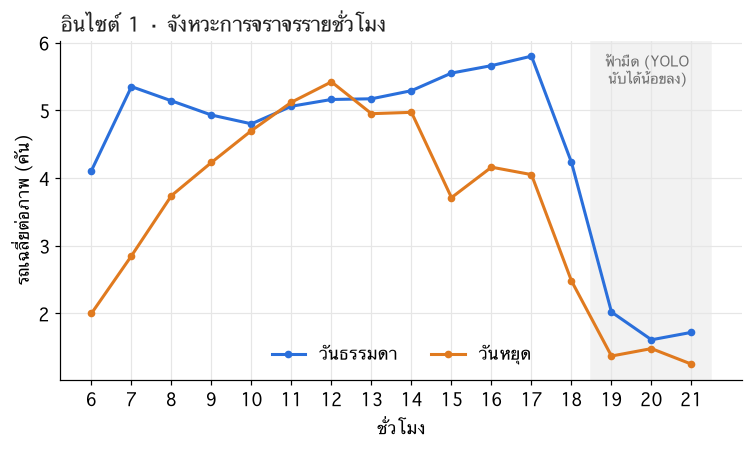

{'weekday_am_peak': {'hour': 7, 'veh': 5.35},
 'weekday_pm_peak': {'hour': 17, 'veh': 5.8},
 'weekend_peak': {'hour': 12, 'veh': 5.42},
 'weekend_vs_weekday_daylight_pct': -20.3,
 'weekday_profile_corr_range': [-0.19, 0.78],
 'weekday_profile_corr_matrix': {'2026-08-25': {'2026-08-25': 1.0,
   '2026-08-26': 0.62,
   '2026-08-27': 0.46,
   '2026-08-28': 0.78,
   '2026-08-31': 0.14},
  '2026-08-26': {'2026-08-25': 0.62,
   '2026-08-26': 1.0,
   '2026-08-27': 0.35,
   '2026-08-28': 0.53,
   '2026-08-31': 0.35},
  '2026-08-27': {'2026-08-25': 0.46,
   '2026-08-26': 0.35,
   '2026-08-27': 1.0,
   '2026-08-28': 0.7,
   '2026-08-31': -0.19},
  '2026-08-28': {'2026-08-25': 0.78,
   '2026-08-26': 0.53,
   '2026-08-27': 0.7,
   '2026-08-28': 1.0,
   '2026-08-31': 0.36},
  '2026-08-31': {'2026-08-25': 0.14,
   '2026-08-26': 0.35,
   '2026-08-27': -0.19,
   '2026-08-28': 0.36,
   '2026-08-31': 1.0}},
 'daylight_hourly_by_date': [{'hour': 6,
   '2026-08-25': 4.33,
   '2026-08-26': 4.66,
   '2026-08

In [3]:
display(Image('reports/figures/i1_hourly_profile.png'))
{k: v for k, v in a['i1'].items() if k != 'hourly_profile'}

## อินไซต์ 2 · เย็น > เช้า, ใกล้รถไฟฟ้า

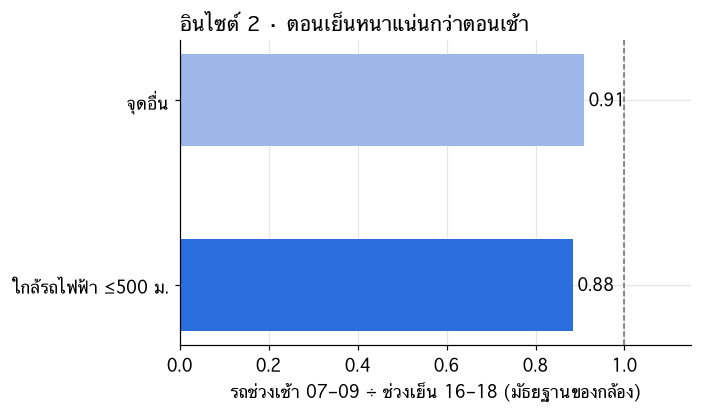

{'cams_evening_heavier': 50,
 'cams_morning_heavier': 23,
 'cams_similar': 27,
 'median_ratio_near_rail_500m': 0.884,
 'n_near_rail': 39,
 'median_ratio_elsewhere': 0.909,
 'mannwhitney_p_near_vs_else': 0.9718,
 'spearman_dist_rail_vs_ratio': {'rho': 0.017, 'p': 0.8691},
 'ratio_by_highway': {'motorway': 0.945,
  'primary': 0.916,
  'secondary': 0.808,
  'tertiary': 0.569,
  'trunk': 0.674},
 'peak_hour_distribution': {'6': 3,
  '7': 12,
  '8': 7,
  '9': 3,
  '10': 4,
  '11': 4,
  '12': 4,
  '13': 3,
  '14': 9,
  '15': 11,
  '16': 12,
  '17': 18,
  '18': 10}}

In [4]:
display(Image('reports/figures/i2_am_pm_rail.png'))
a['i2']

## อินไซต์ 3 · ฝนวันธรรมดา

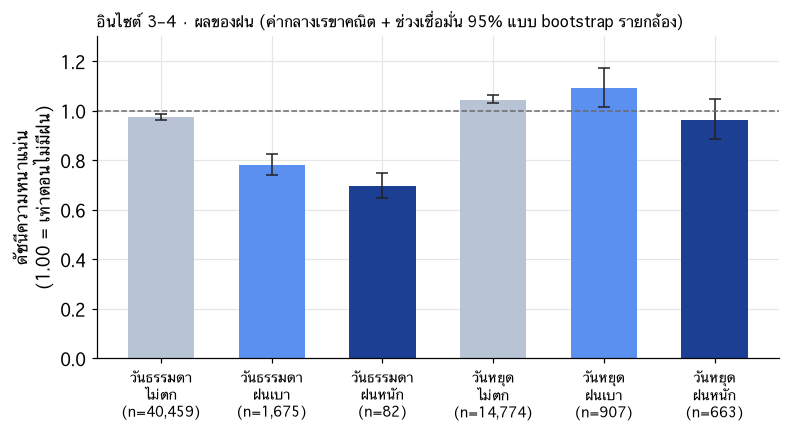

{'all_light': {'dry': {'estimate': 0.973,
   'ci95': [0.962, 0.986],
   'n_images': 40459,
   'n_cams': 100},
  'light': {'estimate': 0.781,
   'ci95': [0.742, 0.824],
   'n_images': 1675,
   'n_cams': 95},
  'heavy': {'estimate': 0.696,
   'ci95': [0.649, 0.748],
   'n_images': 82,
   'n_cams': 9}},
 'daylight_only': {'dry': {'estimate': 0.974,
   'ci95': [0.963, 0.986],
   'n_images': 33835,
   'n_cams': 100},
  'light': {'estimate': 0.864,
   'ci95': [0.811, 0.921],
   'n_images': 787,
   'n_cams': 91},
  'heavy': {'estimate': 0.696,
   'ci95': [0.649, 0.754],
   'n_images': 82,
   'n_cams': 9}},
 'dusk_night': {'dry': {'estimate': 0.97,
   'ci95': [0.945, 0.995],
   'n_images': 6624,
   'n_cams': 100},
  'light': {'estimate': 0.715,
   'ci95': [0.658, 0.777],
   'n_images': 888,
   'n_cams': 87}},
 'mixed_model': {"C(rain_level, Treatment('dry'))[T.heavy]": {'coef': -0.2347,
   'pct_change': -20.9,
   'p': 0.0003},
  "C(rain_level, Treatment('dry'))[T.light]": {'coef': -0.1753,
   

In [5]:
display(Image('reports/figures/i3_i4_rain_effect.png'))
{k: v for k, v in a['i3'].items() if k != 'rain_by_date_hour'}

## อินไซต์ 4 · ฝนวันหยุด + น้ำท่วม

In [6]:
a["i4"]

{'weekend': {'dry': {'estimate': 1.045,
   'ci95': [1.029, 1.064],
   'n_images': 14774,
   'n_cams': 100},
  'light': {'estimate': 1.092,
   'ci95': [1.015, 1.173],
   'n_images': 907,
   'n_cams': 78},
  'heavy': {'estimate': 0.963,
   'ci95': [0.885, 1.048],
   'n_images': 663,
   'n_cams': 80}},
 'flood_sensors': {'images_with_sensor_within_1km': 44948,
  'cams_with_sensor': 75,
  'readings_above_0cm': 0,
  'max_cm': 0.0},
 'unfixed_flood_points': {'cams_with_unfixed_500m': 21,
  'median_rain_ratio_with': 0.943,
  'median_rain_ratio_without': 0.857,
  'mannwhitney_p': 0.2013},
 'dbscan_hotspot': {'cams_in_hotspot_with_rain': 2,
  'median_with': 0.727,
  'median_without': 0.885,
  'mannwhitney_p': None},
 'kde_vs_rain_ratio': {'rho': 0.042, 'p': 0.6814}}

## อินไซต์ 5 · วันหยุดตามสถานที่

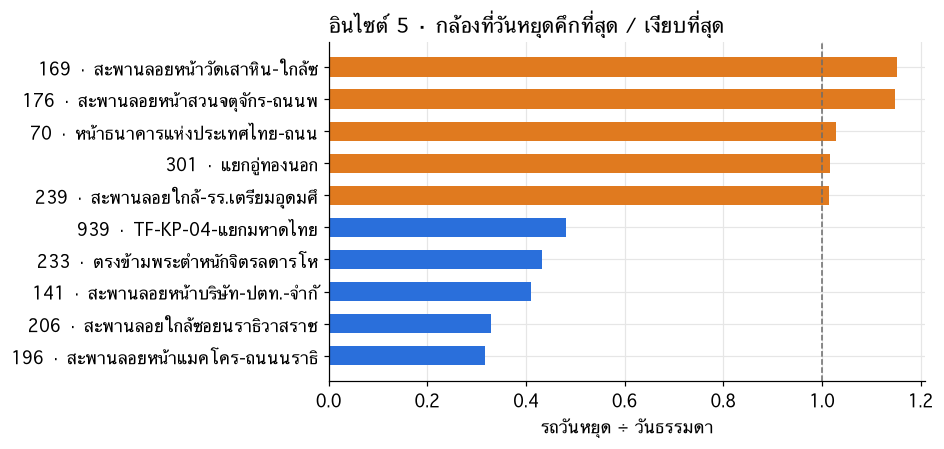

{'top_weekend': [{'cam': 169,
   'name_th': 'สะพานลอยหน้าวัดเสาหิน-ใกล้ซ',
   'name_en': 'Footbridge in front of Wat Sao  Hin  Near Soi Wong Sawang 3 on Wong Sawang Road',
   'district': 'บางซื่อ',
   'veh_weekday': 3.991,
   'veh_weekend': 4.596,
   'weekend_ratio': 1.152,
   'poi_market': 0.0,
   'poi_mall': 0.0,
   'poi_office': 1.0},
  {'cam': 176,
   'name_th': 'สะพานลอยหน้าสวนจตุจักร-ถนนพ',
   'name_en': 'Footbridge in front of Chatuchak Park on Phahon Yothin Road',
   'district': 'บางซื่อ',
   'veh_weekday': 2.021,
   'veh_weekend': 2.318,
   'weekend_ratio': 1.147,
   'poi_market': 0.0,
   'poi_mall': 1.0,
   'poi_office': 0.0},
  {'cam': 70,
   'name_th': 'หน้าธนาคารแห่งประเทศไทย-ถนน',
   'name_en': 'Near Thanachart Bank Public Company Limited,Branch Bang Khunphrom on Sam Sen Road',
   'district': 'พระนคร',
   'veh_weekday': 2.909,
   'veh_weekend': 2.994,
   'weekend_ratio': 1.029,
   'poi_market': 5.0,
   'poi_mall': 0.0,
   'poi_office': 2.0},
  {'cam': 301,
   'name_th': '

In [7]:
display(Image('reports/figures/i5_weekend_ratio.png'))
a['i5']

## อินไซต์ 6 · เขต / ชนิดถนน / วันศุกร์

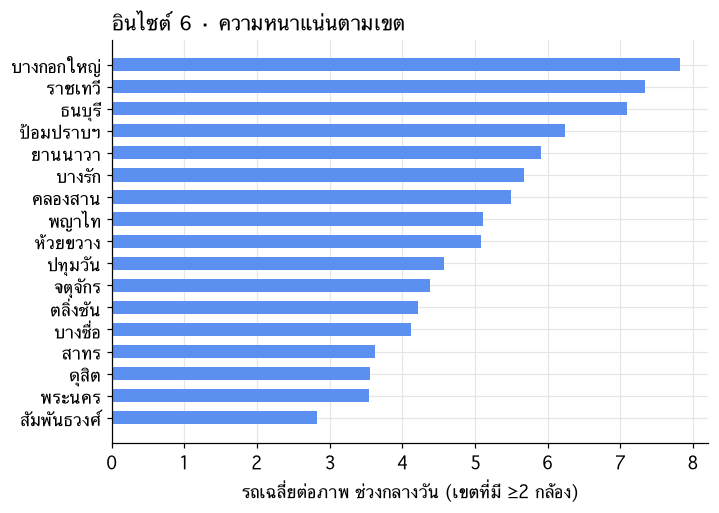

{'district_daylight': [{'district': 'บางกอกใหญ่', 'veh': 7.82, 'cams': 2},
  {'district': 'ราชเทวี', 'veh': 7.34, 'cams': 5},
  {'district': 'ธนบุรี', 'veh': 7.09, 'cams': 6},
  {'district': 'ป้อมปราบฯ', 'veh': 6.24, 'cams': 6},
  {'district': 'ยานนาวา', 'veh': 5.91, 'cams': 4},
  {'district': 'บางรัก', 'veh': 5.68, 'cams': 5},
  {'district': 'คลองสาน', 'veh': 5.49, 'cams': 3},
  {'district': 'พญาไท', 'veh': 5.11, 'cams': 5},
  {'district': 'ห้วยขวาง', 'veh': 5.08, 'cams': 9},
  {'district': 'ปทุมวัน', 'veh': 4.57, 'cams': 5},
  {'district': 'จตุจักร', 'veh': 4.38, 'cams': 13},
  {'district': 'ตลิ่งชัน', 'veh': 4.22, 'cams': 3},
  {'district': 'บางซื่อ', 'veh': 4.12, 'cams': 6},
  {'district': 'สาทร', 'veh': 3.62, 'cams': 3},
  {'district': 'ดุสิต', 'veh': 3.55, 'cams': 8},
  {'district': 'พระนคร', 'veh': 3.54, 'cams': 11},
  {'district': 'สัมพันธวงศ์', 'veh': 2.83, 'cams': 2}],
 'highway_veh_median': [{'highway': 'motorway', 'median': 5.72, 'count': 6},
  {'highway': 'primary', 'media

In [8]:
display(Image('reports/figures/i6_district.png'))
a['i6']

## อินไซต์ 7 · ประเภทรถ

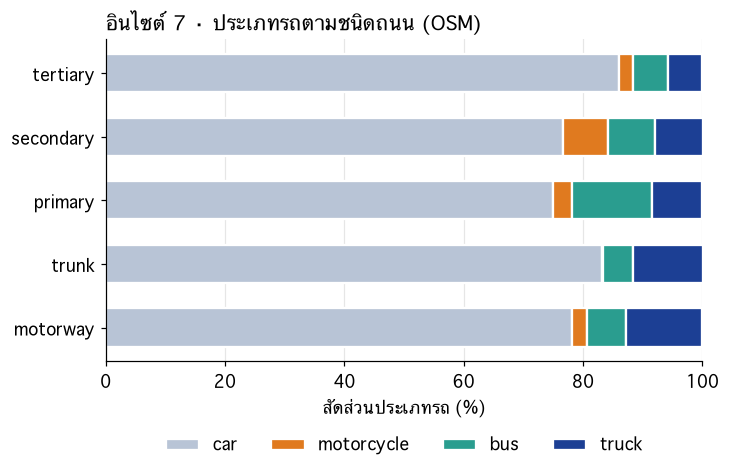

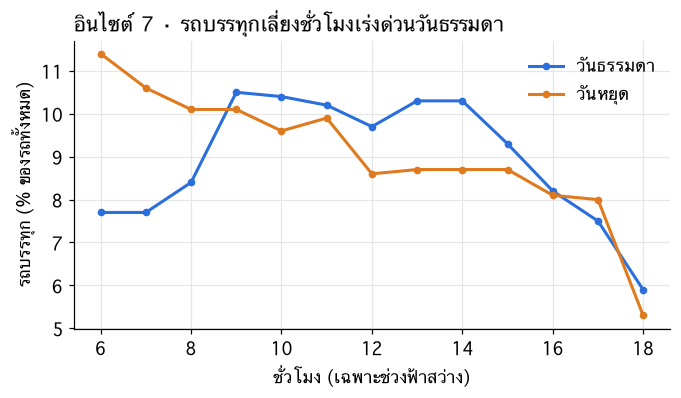

{'share_by_highway_pct': [{'highway': 'motorway',
   'car': 78.1,
   'motorcycle': 2.5,
   'bus': 6.6,
   'truck': 12.8},
  {'highway': 'primary',
   'car': 74.9,
   'motorcycle': 3.2,
   'bus': 13.4,
   'truck': 8.5},
  {'highway': 'secondary',
   'car': 76.7,
   'motorcycle': 7.4,
   'bus': 7.9,
   'truck': 8.1},
  {'highway': 'tertiary',
   'car': 86.0,
   'motorcycle': 2.3,
   'bus': 6.0,
   'truck': 5.7},
  {'highway': 'trunk',
   'car': 83.1,
   'motorcycle': 0.2,
   'bus': 5.1,
   'truck': 11.7}],
 'overall_share_pct': {'car': 76.3,
  'motorcycle': 4.3,
  'bus': 10.8,
  'truck': 8.6},
 'moto_vs_food_spearman': {'rho': 0.214, 'p': 0.0323},
 'top_moto_cams': [{'cam': 603,
   'name_th': 'BR-05-01-แยกสีลม-นราธิวาส',
   'district': 'บางรัก',
   'moto_share': 0.349,
   'poi_food': 72.0,
   'poi_office': 26.0},
  {'cam': 500,
   'name_th': 'ทางแยกมิตรสัมพันธ์',
   'district': 'ปทุมวัน',
   'moto_share': 0.26,
   'poi_food': 37.0,
   'poi_office': 0.0},
  {'cam': 371,
   'name_th': 'แยก

In [9]:
display(Image('reports/figures/i7_vehicle_mix.png'))
display(Image('reports/figures/i7_truck_by_hour.png'))
a['i7']